# Cell trees with Bonsai

*Gregor Lueg*

## Intro

UMAP and t-SNE squash a kNN graph into two dimensions and lose most of the
global structure on the way.
[Bonsai (de Groot, et al., Nat. Biotechnol., 2026)](https://www.nature.com/articles/s41587-026-03220-2)
takes a different route: it reconstructs a tree over the cells, every cell a
leaf and every internal node an inferred ancestral state, with branch lengths
that carry how much changed between them. The tree is the representation; a
2D layout is just a way to draw it.

What makes it work is that Bonsai uses the error bar on every measurement, not
only the measurement. Those come from
[Sanity (Breda, et al., Nat. Biotechnol., 2021)](https://www.nature.com/articles/s41587-021-00875-x),
which turns raw UMI counts into posterior log fold changes with error bars,
gene by gene. `bv.trees.bonsai()` runs both: counts from disk, Sanity, Bonsai,
layout. Both are Rust ports under the hood,
[`sanity-sc-rs`](https://github.com/GregorLueg/sanity-sc-rs) and
[`bonsai-rs`](https://github.com/GregorLueg/bonsai-rs).

We use the PBMC3k data here. If you have not worked through the
[PBMC vignette](pbmc_single_cell.ipynb), do that first; the preprocessing
below is the same, just condensed.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.collections import LineCollection

import bixverse as bv
import bixverse.embed
from bixverse.params import NeighboursParams

## Preparing the data

Loading, QC and the usual HVG, PCA, neighbours and clustering chain. Bonsai
itself needs none of the last four, but the clusters and cell types make the
tree readable, and the UMAP gives us something to compare against.

In [2]:
pbmc3k_path = bv.io.download_pbmc3k()
tempdir_pbmc = tempfile.TemporaryDirectory()

# load
sc = bv.io.load_mtx(
    Path(tempdir_pbmc.name) / "pbmc3k",
    bv.io.get_cell_ranger_params(pbmc3k_path),
)

sc.rename_var_col("column1", "gene_symbol")
var = sc.var()

# doublets
scrublet_res = bv.doublets.scrublet(sc)
sc.add_obs(bv.doublets.get_data(scrublet_res))

sc.set_cells_to_keep(
    sc.obs(cols=["cell_id", "doublet"]).filter(~pl.col("doublet"))["cell_id"].to_list()
)

# qc
bv.qc.gene_set_proportions(
    sc,
    {"MT": var.filter(pl.col("gene_symbol").str.contains("^MT-"))["gene_id"].to_list()},
    streaming=False,
)

qc_df = sc.obs(cols=["cell_id", "lib_size", "nnz", "MT"], filtered=True)
qc = bv.qc.run_cell_qc(
    {
        "log10_lib_size": np.log10(qc_df["lib_size"].to_numpy()),
        "log10_nnz": np.log10(qc_df["nnz"].to_numpy()),
        "MT": qc_df["MT"].to_numpy(),
    },
    sc.cells_to_keep,
    directions={
        "log10_lib_size": "twosided",
        "log10_nnz": "twosided",
        "MT": "above",
    },
    threshold=3.0,
)
sc.set_cells_to_keep(qc.cell_idx[~qc.combined])

# hvg, pca, knn, clustering, umap
bv.pp.find_hvg(sc, hvg_no=2000)
bv.pp.calculate_pca(sc, no_pcs=30, verbose=True)
bv.graph.find_neighbours(
    sc, neighbours_params=NeighboursParams(knn_method="exhaustive")
)
bv.graph.find_clusters(sc, res=1.0, name="leiden_clusters")
bv.embed.umap(sc)

sc

Sparse PCA: Loaded in data in 7.57ms
Sparse PCA: finished the data preparations in 1.47ms


Sparse PCA: finished calculations in 222.04ms
Sparse PCA: total run time -> 231.15ms


SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmple7ie39i/pbmc3k',
  cells=2700 (kept 2399), genes=11139,
  hvg=True, pca=True, embeddings=['umap'],
  knn=True, graph=True, magic=False, residuals=False,
  stale=none
)

Cell types via scType, with the same markers as the PBMC vignette.

In [3]:
cell_markers = {
    "CD3D": "T cells",
    "CD3E": "T cells",
    "IL7R": "CD4+ T",
    "CD4": "CD4+ T",
    "CD8A": "CD8+ T",
    "CD8B": "CD8+ T",
    "MS4A1": "B cells",
    "CD79A": "B cells",
    "CD14": "CD14+ Mono",
    "LYZ": "CD14+ Mono",
    "FCGR3A": "CD16+ Mono",
    "CDKN1C": "CD16+ Mono",
    "GNLY": "NK",
    "NKG7": "NK",
    "FCER1A": "mDC",
    "CD1C": "mDC",
    "LILRA4": "pDC",
    "PPBP": "Platelet",
    "PF4": "Platelet",
}

cell_markers_df = pl.DataFrame(
    {"gene_symbol": list(cell_markers), "cell_type": list(cell_markers.values())}
).join(var.select("gene_symbol", "gene_id"), on="gene_symbol")

sctype_scores = bv.annotate.calc_sc_type_scores(
    sc, bv.annotate.prepare_cell_markers(sc, cell_markers_df)
)
obs = sc.obs(cols=["cell_idx", "leiden_clusters"], filtered=True)
cell_type_anno = bv.annotate.score_clusters(
    sctype_scores, obs["leiden_clusters"].to_numpy()
)

sc.add_obs(
    obs.join(
        cell_type_anno.select(
            pl.col("cluster_id").alias("leiden_clusters"), "cell_type"
        ),
        on="leiden_clusters",
        how="left",
    ).select("cell_idx", "cell_type")
)

## Running Bonsai

One call. No HVG selection needed: by default every gene is a candidate, and
Sanity streams them through in chunks of 1,024, keeping only the genes with
enough signal over their own noise (`min_signal_to_noise` in `BonsaiParams`,
1 by default). That is the gene selection of the Bonsai paper. Memory stays at
one chunk of counts plus the survivors, whatever the number of candidates.

In [4]:
tree = bv.trees.bonsai(sc, verbose=True)

tree

 Sanity chunk 1/11: kept 38 of 1024 genes (38 kept so far, 1.13s).


 Sanity chunk 2/11: kept 24 of 1024 genes (62 kept so far, 2.14s).


 Sanity chunk 3/11: kept 25 of 1024 genes (87 kept so far, 3.00s).


 Sanity chunk 4/11: kept 43 of 1024 genes (130 kept so far, 4.11s).


 Sanity chunk 5/11: kept 23 of 1024 genes (153 kept so far, 5.04s).


 Sanity chunk 6/11: kept 28 of 1024 genes (181 kept so far, 5.97s).


... (8 outputs left out)

  loglik -5.049643e5, gain +4.979e0 (232.66ms)
Step 7: branch lengths...


  loglik -5.046906e5, gain +2.737e2 (654.51ms)
Step 8: collapse zero-length edges...


  loglik -5.046898e5, gain +7.762e-1 (534.47ms)
Bonsai finished in 52.25 s.
Layout of 4657 nodes in 0.00 s.


BonsaiTree: 2399 leaves, 2258 inferred ancestors
  Genes: 348 used, 10791 dropped
  Loglikelihood: -504689.8
  Layout: equal_angle
  Seconds: sanity 12.3 | ingest 0.0 | bonsai 52.2 | layout 0.0 | total 64.6

Where did the time go? Every stage is timed, and `total` is the whole call as
Python saw it, so a gap between `total` and the stages would be time spent
somewhere nobody measured. Sanity fits every one of the 11k candidate genes,
the search only sees the few hundred that survive but has to place 2,400
leaves, and on PBMC3k the search ends up taking the bigger share.

In [5]:
tree.timings

stage,seconds
str,f64
"""sanity""",12.303411
"""ingest""",0.009291
"""bonsai""",52.248725
"""layout""",0.000069
"""total""",64.563107


The search reports its steps too: the loglikelihood after each and what it
took. Steps 4 and 7 re-fit the branch lengths, 5 and 6 rearrange the tree
(subtree pruning and regrafting, then nearest-neighbour interchanges), and 8
collapses the zero-length edges the rest leave behind.

In [6]:
tree.steps

step,loglik,seconds
str,f64,f64
"""1-2 linkage""",-760924.319445,0.445099
"""3 polytomy""",-760924.319445,0.015592
"""4 branch""",-518298.530244,4.471237
"""5 spr""",-504969.253702,45.890001
"""6 nni""",-504964.27491,0.23266
"""7 branch""",-504690.586508,0.654507
"""8 collapse""",-504689.810319,0.53447


### Which genes made it?

Most genes carry no usable signal over their Poisson noise and are dropped.
The ones that stay overlap with, but are not, the HVGs.

In [7]:
hvg_ids = set(sc.gene_ids(sc.map.hvg))

pl.DataFrame(
    {
        "genes_used": [len(tree.genes_used)],
        "genes_dropped": [len(tree.genes_dropped)],
        "also_hvg": [sum(g in hvg_ids for g in tree.genes_used)],
    }
)

genes_used,genes_dropped,also_hvg
i64,i64,i64
348,10791,219


Want the tree on your own gene set instead? Pass `hvg` (0-based), e.g.
`bv.trees.bonsai(sc, hvg=sc.map.hvg)`. The signal-to-noise filter still
applies on top.

## Plotting

There is no tree plot in `bv.pl` yet, so here is a short matplotlib one: every
branch as a segment from a node to its parent and a point per leaf. Radial
layouts get straight branches at a fixed aspect ratio, the dendrogram right
angles. `colour_by` takes one value per leaf, in the order of the object's
kept cells.

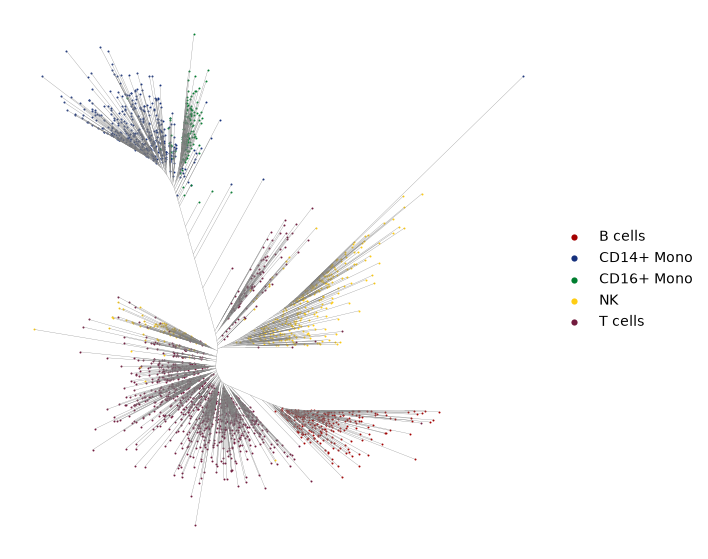

In [8]:
def plot_tree(tree, colour_by=None, point_size=2.0, size_by_cells=False, ax=None):
    ax = ax or plt.subplots(figsize=(7, 7))[1]
    nodes = tree.nodes
    xy = nodes.select("x", "y").to_numpy()
    edges = nodes.filter(pl.col("parent").is_not_null())
    child = xy[edges["node"].to_numpy()]
    parent = xy[edges["parent"].to_numpy()]
    if tree.layout == "dendrogram":
        # depth along x, leaves along y: across to the parent's depth, then up
        elbow = np.column_stack([parent[:, 0], child[:, 1]])
        segs = np.concatenate(
            [np.stack([child, elbow], 1), np.stack([elbow, parent], 1)]
        )
    else:
        segs = np.stack([child, parent], 1)
        ax.set_aspect("equal")
    ax.add_collection(LineCollection(segs, colors="grey", linewidths=0.2))

    leaves = nodes.filter(pl.col("is_leaf"))
    sizes = point_size
    if size_by_cells:
        n = leaves["n_cells"].to_numpy()
        sizes = point_size * (1 + 4 * (n - n.min()) / max(n.max() - n.min(), 1))
    if colour_by is None:
        ax.scatter(leaves["x"], leaves["y"], s=sizes, linewidths=0)
    else:
        colour_by = np.asarray(colour_by)
        groups = np.unique(colour_by)
        palette = bv.pl.bx_colors("main", n=len(groups))
        for i, grp in enumerate(groups):
            m = colour_by == grp
            s = sizes[m] if size_by_cells else sizes
            ax.scatter(
                leaves["x"].to_numpy()[m],
                leaves["y"].to_numpy()[m],
                s=s,
                color=palette[i],
                label=grp,
                linewidths=0,
            )
        legend = ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
        for handle in legend.legend_handles:
            handle.set_sizes([20])
    ax.set_axis_off()
    return ax


cell_type = sc.obs(cols=["cell_type"], filtered=True)["cell_type"].to_numpy()

plot_tree(tree, colour_by=cell_type)
plt.show()

Every cell type gets its own subtree, and none of that was told to Bonsai: the
annotation only colours the leaves. The CD16+ monocytes sit inside the
monocyte subtree rather than next to it, and the NK cells branch off close to
the T cells, which is what you would expect from their biology. Branch length
is change, so the long isolated branches are cells that look like nothing
else in the data.

The default is the equal-angle layout: every subtree gets a wedge
proportional to its size. Two alternatives, recomputed from the stored tree
with `relayout_bonsai()` without searching again. The dendrogram draws the
branch lengths along x:

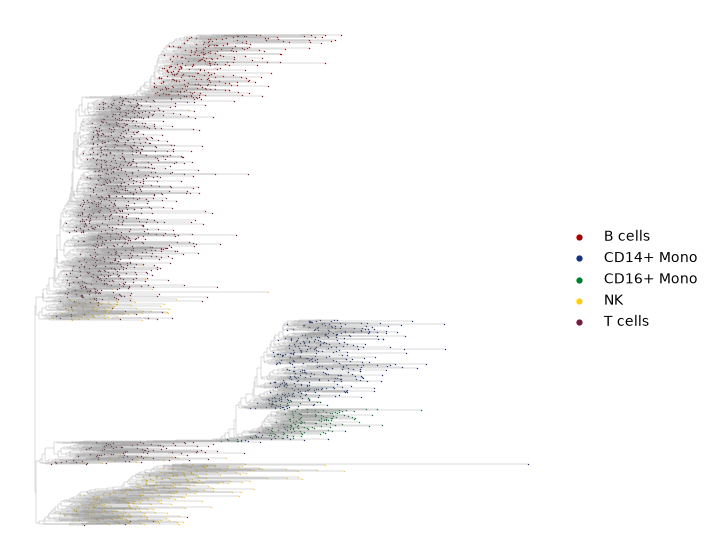

In [9]:
plot_tree(
    bv.trees.relayout_bonsai(tree, layout="dendrogram"),
    colour_by=cell_type,
    point_size=1.0,
)
plt.show()

The hyperbolic projection maps the same layout onto the unit disk. How much
it changes the picture depends on how far the tips sit from the root; on
PBMC3k the branches are short and it barely does, on deeper trees it gives
the crowded centre more room:

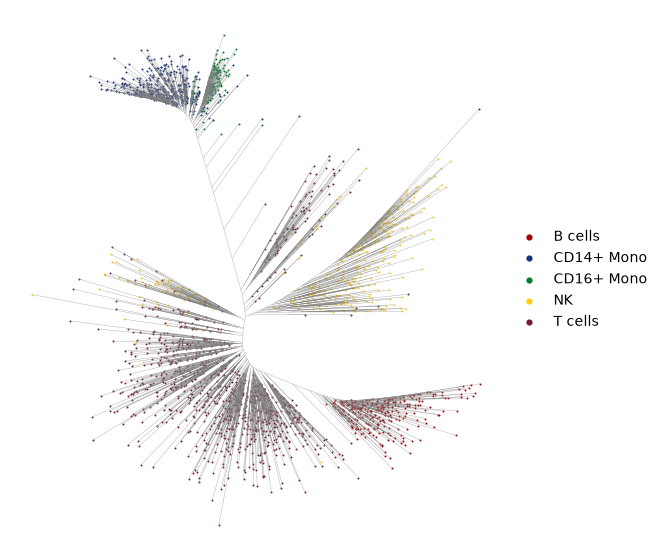

In [10]:
plot_tree(bv.trees.relayout_bonsai(tree, hyperbolic=True), colour_by=cell_type)
plt.show()

`relayout_bonsai()` returns a new tree and leaves the original alone, so keep
the result if you want that layout for the next step.

## Bonsai next to UMAP

The leaf coordinates can go into the object as an embedding, so everything
that plots embeddings works on them.

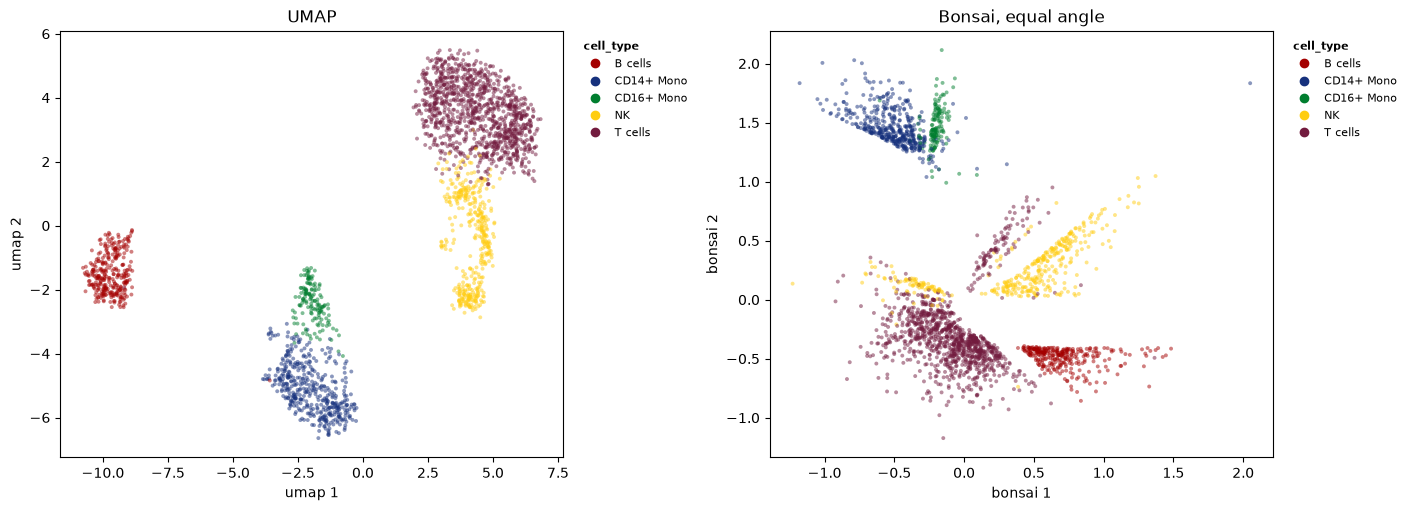

In [11]:
bv.trees.set_bonsai_embedding(sc, tree)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")
bv.pl.embedding_plot(sc, "umap", "cell_type", discrete=True, ax=axes[0])
axes[0].set_title("UMAP")
bv.pl.embedding_plot(sc, "bonsai", "cell_type", discrete=True, ax=axes[1])
axes[1].set_title("Bonsai, equal angle")
plt.show()

## Bonsai on metacells

At 100k cells a tree over every cell is slow and hard to look at. Metacells
compress first. Their raw counts are sums over their cells, and a sum of
Poisson counts is Poisson, so Sanity treats a metacell exactly as it treats a
cell, with its total counts as the library size. A metacell of 20 cells has
about 20 times the counts, so its error bars are much tighter, and Bonsai
weights by them. The same `bonsai()` call works on `MetaCells`; every
metacell becomes a leaf.

Here SuperCells compresses the PBMCs into metacells, and each metacell gets
the cell type most of its cells carry.

In [12]:
supercells = bv.metacells.generate_supercells(sc)

bv.metacells.calc_meta_cell_purity(
    supercells, cell_type.tolist(), add_additional_info="top_label"
)

tree_mc = bv.trees.bonsai(supercells, verbose=True)

tree_mc

 Sanity chunk 1/11: kept 216 of 1024 genes (216 kept so far, 352.54ms).


 Sanity chunk 2/11: kept 215 of 1024 genes (431 kept so far, 747.21ms).


 Sanity chunk 3/11: kept 192 of 1024 genes (623 kept so far, 1.14s).


 Sanity chunk 4/11: kept 217 of 1024 genes (840 kept so far, 1.43s).


 Sanity chunk 5/11: kept 180 of 1024 genes (1020 kept so far, 1.72s).


 Sanity chunk 6/11: kept 183 of 1024 genes (1203 kept so far, 2.04s).


... (5 outputs left out)

  loglik -1.471334e5, gain +7.820e4 (188.79ms)
Step 5: SPR...


  loglik -1.452109e5, gain +1.922e3 (933.57ms)
Step 6: NNI...
  loglik -1.452109e5, gain +0.000e0 (25.85ms)
Step 7: branch lengths...


  loglik -1.451410e5, gain +6.991e1 (222.41ms)
Step 8: collapse zero-length edges...
  loglik -1.451410e5, gain +2.685e-4 (106.53ms)
Bonsai finished in 1.50 s.
Layout of 224 nodes in 0.00 s.


BonsaiTree: 120 leaves (2399 cells), 104 inferred ancestors
  Genes: 2228 used, 8911 dropped
  Loglikelihood: -145141.0
  Layout: equal_angle
  Seconds: sanity 3.6 | ingest 0.0 | bonsai 1.5 | layout 0.0 | total 5.1

The same PBMCs as 120 metacells, in a fraction of the time the cell-level
tree took. And the summed counts are deep enough that thousands of
genes clear the signal-to-noise bar, against a few hundred for single cells,
so the tree sees far more of the transcriptome.

`size_by_cells=True` scales every leaf by the cells behind it.

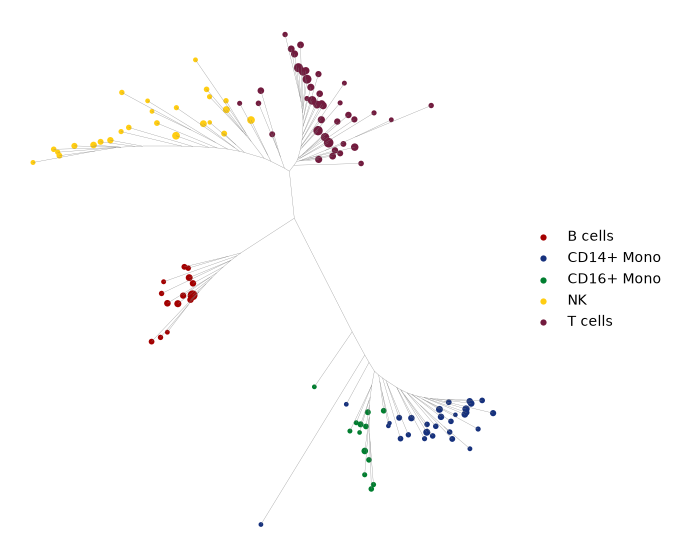

In [13]:
plot_tree(
    tree_mc,
    colour_by=supercells.obs(cols=["mc_top_label"])["mc_top_label"].to_numpy(),
    size_by_cells=True,
    point_size=10.0,
)
plt.show()

The subtrees of the cell-level tree survive the compression, and the
monocytes come out sharper: CD14+ and CD16+ split into two branches of one
monocyte subtree. A few T-cell metacells sit on the NK branch; T and NK cells
share much of their cytotoxic programme, so that is where the tree is least
sure of the labels. What the metacell tree cannot show is anything inside a
metacell, so pick the compression to match the resolution you care about.

## Scaling

The search grows a little faster than linearly with the cell number. In
`bonsai-rs`'s own benchmarks on ten cores it took about 70 seconds at 10,000
cells and 210 seconds at 25,000. Sanity comes on top and grows with the
number of candidate genes; CPU has been made fast, GPU is even faster.
`bixverse_gpu.trees.bonsai()` takes the same arguments, returns the same
`BonsaiTree`, and runs Sanity on the device.

On 10,000 simulated cells with all 16,974 genes as candidates (M1 Max, ten
cores):

| | Sanity | Bonsai search | total |
|---|---|---|---|
| CPU | 60 s | 80 s | 140 s |
| GPU | 5 s | 80 s | 65 s |

Both kept the same 2,751 genes. With Sanity on the GPU the tree search is the
clear cost, and that is where 100k cells will hurt. Metacells are the way
around it: compress first and the tree has a few thousand leaves instead of
100k.

## Clean up

In [14]:
tempdir_pbmc.cleanup()